# Modelling

Today, we will take a closer look at the core of the modelling process: model training. We will learn how to input data into the model in order to identify patterns and relationships. Regarding the models used in today's exercise, we will examine a very common implementation provided by the Scikit Learn library. Once again, we will use the [bike](https://www.kaggle.com/datasets/lakshmi25npathi/bike-sharing-dataset) and [UCI heart disease](https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data) datasets to predict the daily number of bicycles rented and whether a patient has heart disease, respectively.

We will have a look at the following models:
* Linear Regression
* Logistic Regression
* Decision Trees

And how to evaluate the results of regression and classification models.

## Dataset Descriptions

Before we begin, we would like to re-introduce the two datasets used in the exercise.

### Bike Dataset

The "Bike Dataset" is retrieved from [Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/bike-sharing-dataset) and contains the daily count of rental bikes between the years 2011 and 2012 in the Capital bike share system (Washington D.C., USA). We work with a slightly adjusted version of the dataset that contain the variables listed below.

| Columnn   | Description  |
| --------- | ------------ |
| `dteday` | Date |
| `season` | `1` winter, `2` spring, `3` summer, `4` fall (incorrectly stated in the [description in Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/bike-sharing-dataset/data))! |
| `yr` | Year (`0` 2011, `1` 2012) |
| `mnth` | Month ( `1` to `12`) |
| `hr` | Hour (`0` to `23`) |
| `holiday` | Weather day is holiday or not (extracted from [Web Link](http://www.freemeteo.com)) |
| `weathersit` | `1`: Clear, Few clouds, Partly cloudy, Partly cloudy<br>`2`: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist<br>`3`: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds<br>`4`: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog |
| `temp` | Temperature in Celsius (only in hourly scale) |
| `atemp` | Feeling temperature in Celsius (only in hourly scale) |
| `hum` | Humidity |
| `windspeed` | Wind speed |
| ========= | ================================================================ |
| `cnt` | Count of total rental bikes including both casual and registered |


### UCI Heart Disease Data

The "UCI Heart Disease Data" is a dataset retrieved from [Kaggle](https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data). There it is introduced as follows:

> One of the major tasks on this dataset is to predict based on the given attributes of a patient that whether that particular person has heart disease or not and other is the experimental task to diagnose and find out various insights from this dataset which could help in understanding the problem more.

It is composed of the following 14 attributes:

| Name | Description | Values |
| ---- | ----------- | ------ |
| id | Unique id for each patient | |
| age | Age of the patient in years | |
| origin | Place of study | Cleveland, Hungary, Switzerland, VA Long Beach |
| sex | The patient's gender | Male / Female |
| cp | Chest pain type | typical angina, atypical angina, non-anginal, asymptomatic |
| trestbps | Resting blood pressure (in mm Hg on admission to the hospital) | |
| chol | Serum cholesterol in mg/dl | |
| fbs | If fasting blood sugar > 120 mg/dl | True / False |
| restecg | Resting electrocardiographic results | normal, st-t abnormality, lv hypertrophy |
| thalach | Maximum heart rate achieved | |
| exang | Exercise-induced angina | True / False |
| oldpeak | ST depression induced by exercise relative to rest | |
| slope | The slope of the peak exercise ST segment | downsloping, flat, upsloping |
| ca | Number of major vessels colored by fluoroscopy | 0-3 |
| thal | Thalassemia | Normal, fixed defect, reversible defect |
| num | The predicted attribute | 0: no heart disease<br>1: mild heart disease<br>2: moderate heart disease<br>3: severe heart disease<br>4: critical heart disease |

For further information see here: https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data

While we're at it, let's load our dataframes as well. We will also perform a few preprocessing steps as already shown in the previous exercise.

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd

In [3]:
# Load the bike data
df = pd.read_csv('bikes.csv')

# Perform a little preprocessing
df['cnt'] = df['cnt'].astype('UInt16')
df['dteday'] = pd.to_datetime(df['dteday'])
df['windspeed'] = df['windspeed'].replace('-', None).astype('float')
df[['mnth', 'weathersit']] = df[['mnth', 'weathersit']].astype('UInt8')
df['season'] = df['season'].replace({1:'winter', 2:'spring', 3:'summer', 4:'fall'})
df

,dteday,season,yr,mnth,hr,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,winter,0,1,0,0,1,3.28,3.0014,81.0,0.0000,16
1,2011-01-01,winter,0,1,1,0,<NA>,2.34,1.9982,80.0,0.0000,40
2,2011-01-01,winter,0,<NA>,2,0,1,2.34,1.9982,80.0,0.0000,32
3,2011-01-01,winter,0,1,3,0,1,3.28,3.0014,75.0,0.0000,13
4,2011-01-01,winter,0,1,4,0,1,3.28,3.0014,75.0,0.0000,1
...,...,...,...,...,...,...,...,...,...,...,...,...
17374,2012-12-31,winter,1,<NA>,19,0,<NA>,4.22,1.0016,60.0,11.0014,119
17375,2012-12-31,winter,1,<NA>,20,0,<NA>,4.22,1.0016,60.0,11.0014,89
17376,2012-12-31,winter,1,<NA>,21,0,<NA>,4.22,1.0016,60.0,11.0014,90
17377,2012-12-31,winter,1,12,22,0,1,4.22,1.9982,56.0,8.9981,61


In [44]:
# Load UCI heart disease dataset
df_uci = pd.read_csv('heart_disease_uci.csv', index_col=0)
df_uci

,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2


## Basic Concept and Terminology

Machine learning models (including regression models such as linear regression) are algorithms that aim to predict an output value based on input features.

* **Input features**, also known as independent variables, represent characteristics or attributes. For instance features could include 'height', 'weight', 'gender', and so on. These features can be represented by one vector per obbservation, typically denoted as $ x_i $. If we have data for multiple observations, these vectors can be organized into a matrix $ X $, with each row representing one individual.

* The **output variable** in so called **regression tasks** is a continuous value, while in **classification tasks** it is a class label. For example, in a regression problem predicting house prices, the output variable could be the price of a house. The output in a classification problem could be the name of an animal in an image. This output value for an observation is often denoted as $ y_i $. When we have data for multiple instances, the output values can be arranged in a vector $ y $.

    Can you anwser the following two questions: What type of learning task is it

    * if we want to predict the number of bike rentals per hour?
    * if we want to predict, weather a person has a heart disease or not?

The machine learning model $ f $ endeavors to find a function that maps the input features $ x_i $ to the corresponding output value $ y_i $, such that $ f(x_i) = y_i $. Here, $ y $ serves as the target variable or dependent variable. Additionally, $ y_i $ is commonly referred to as the label associated with $ x_i $.

## Split Feature Matrix and Target Variable

In what is known as supervised machine learning (as we want to show here), we feed the model the training data as a feature matrix $X$ and target variable $y$. We therefore have to split the data accordingly.

But first we have to consider another problem: Many of the machine learning models can handle only numerical data. We therefore somehow have to find a solution for categorical data or missing values. You will learn some techniques to tackle that problems in the next session. But for now let's stick to the most simple solution:
* We simply ignore categorical data and train our models only with on numerical variables
* We only use observations without missing values and drop others

For the missing values of `mnth` there is a simple solution, we can infer them from the `dteday` variable. We take that opportunity to not loose that much data for now.  Further we drop the categorical values with `select_dtypes`.

In [5]:
# Compute (missing) months from dteday
df['mnth'] = df['dteday'].dt.month
# Only select features of the type 'number' and drop rows with missing values.
df_complete = df.select_dtypes('number').dropna()
df_complete

,yr,mnth,hr,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,0,1,0,0,1,3.28,3.0014,81.0,0.0000,16
2,0,1,2,0,1,2.34,1.9982,80.0,0.0000,32
3,0,1,3,0,1,3.28,3.0014,75.0,0.0000,13
4,0,1,4,0,1,3.28,3.0014,75.0,0.0000,1
5,0,1,5,0,2,3.28,1.0016,75.0,6.0032,1
...,...,...,...,...,...,...,...,...,...,...
17368,1,12,13,0,2,4.22,1.0016,44.0,11.0014,203
17370,1,12,15,0,2,5.16,3.0014,45.0,8.9981,315
17372,1,12,17,0,2,4.22,3.0014,48.0,6.0032,164
17377,1,12,22,0,1,4.22,1.9982,56.0,8.9981,61


Now we can split our dataset into feature matrix `X` and target variable `y`.

In [6]:
# Remove target variable from feature matrix and select only numerical typess
X = df_complete.drop(columns=['cnt'])
X

,yr,mnth,hr,holiday,weathersit,temp,atemp,hum,windspeed
0,0,1,0,0,1,3.28,3.0014,81.0,0.0000
2,0,1,2,0,1,2.34,1.9982,80.0,0.0000
3,0,1,3,0,1,3.28,3.0014,75.0,0.0000
4,0,1,4,0,1,3.28,3.0014,75.0,0.0000
5,0,1,5,0,2,3.28,1.0016,75.0,6.0032
...,...,...,...,...,...,...,...,...,...
17368,1,12,13,0,2,4.22,1.0016,44.0,11.0014
17370,1,12,15,0,2,5.16,3.0014,45.0,8.9981
17372,1,12,17,0,2,4.22,3.0014,48.0,6.0032
17377,1,12,22,0,1,4.22,1.9982,56.0,8.9981


In [7]:
# Assign target variable to y
y = df_complete['cnt']
y

0         16
2         32
3         13
4          1
5          1
        ... 
17368    203
17370    315
17372    164
17377     61
17378     49
Name: cnt, Length: 11618, dtype: UInt16

## Lineare Regression

As the name suggests, linear regression tries to model a linear relationship between one or more independent variables (inputs/features) and a dependent variable (target). Linear regression models can be classified by the number of input features. If there is only one independent variable, it is called simple linear regression. If there are multiple independent variables, it is called multiple linear regression. Let's take a look at both.


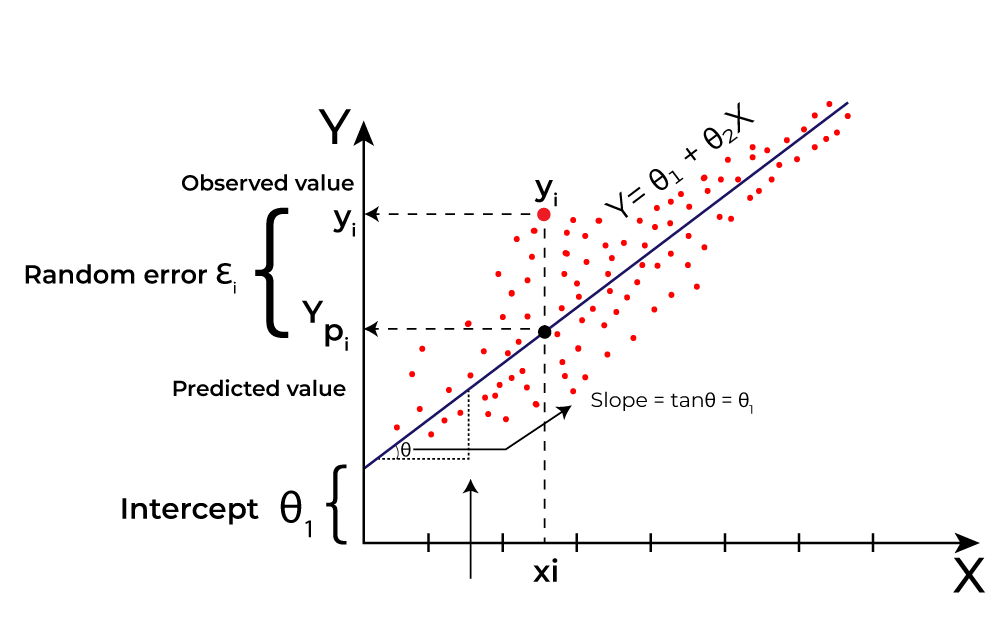


### Simple Linear Regression

One of the simplest models you can think of is the **simple linear regression** model. Here you have only one input feature to predict the output, so it is univariate (that is why it is called simple). In this exercise, you will not only train such a model, but also implement it yourself. The most common simple linear regression model uses ordinary least squares (OLS). This is the one we are going to implement. It is written as
$$\hat{y} = ax + b$$
where
* $\hat{y}$ is the prediction
* $x$ is the feature value
* $b$ is the intercept and
* $a$ is the slope (or coefficient)

The following plot shows `temp` as the independent variable and `cnt` as the target variable. The orange line is the result of a simple linear regression. If there is a clear dependency between the target and the independent variable, one feature might be enough. However, in most cases, this is an oversimplification. In the case of `temp` and `cnt`, we can see a trend (positive correlation), but the results are not very satisfactory. So, let's move on to multiple linear regression to see if we can achieve a better fit by using more than one independent variable.

<Axes: xlabel='temp', ylabel='cnt'>

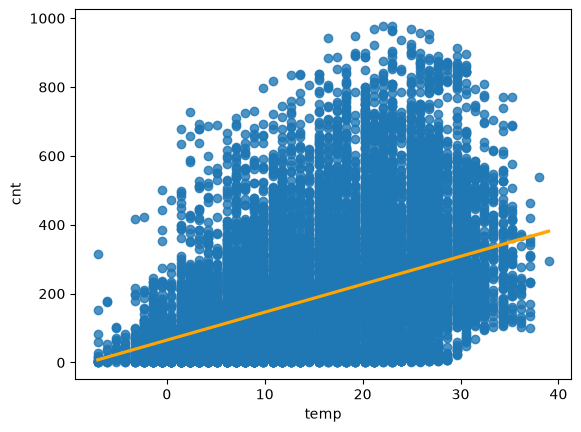

In [8]:
# Create a regression plot of cnt against temp
sns.regplot(df[~df['cnt'].isnull()], x='temp', y='cnt', line_kws={'color':'orange'})

c:\Users\anton_zkhbygp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


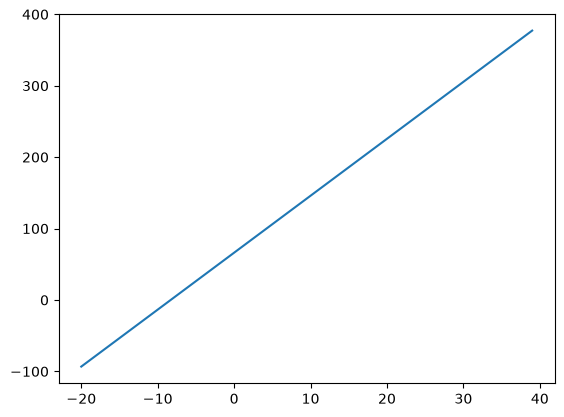

In [9]:
# lets create a very simple linear regression model.
X_reduced = X[["temp"]] # only one fetaure is used

# Import the regression model
from sklearn.linear_model import LinearRegression

# Instantiate the model and train it
lr = LinearRegression()
lr.fit(X_reduced, y)

x_ = np.array(range(-20,40,1)).reshape(-1, 1) # [-20,-19,....,39]
y_ = lr.predict(x_)

plt.plot(x_,y_)
plt.show()

### Exercise 1:
Build Your Own Simple Linear Regression

Using the dataset X and target y, pick one different feature from X (not "temp").
Then:

1. Create a reduced feature matrix X_student using your chosen feature.

2. Train a LinearRegression model on that single feature.

3. Predict values for a reasonable range of input values.

4. Plot the regression line.

c:\Users\anton_zkhbygp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


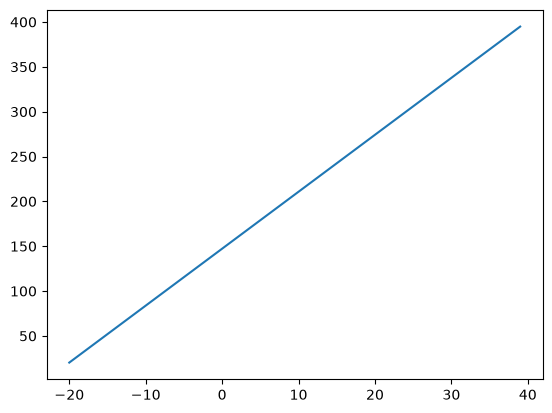

In [10]:
# Create a very simple linear regression model (one feature).
X_student =X[["mnth"]]
# Instantiate the model and train it
lr.fit(X_student, y)

x_ = np.array(range(-20,40,1)).reshape(-1, 1) # [-20,-19,....,39]
y_ = lr.predict(x_)

plt.plot(x_,y_)
plt.show()



### Multiple Linear Regression

In a simple linear regression model, there is only one input feature and one coefficient. For multiple linear regression, we are now considering multiple input features, each of which has a coefficient.
For a prediction $\hat{y}$, an intercept $a$, coefficients $b, c, d, \dots$ and feature variables $x_1, x_2, x_3, ...$ a model for multivariate linear regression is defined as:

$$\hat{y} = a + bx_1 + cx_2 + dx_3 + \dots$$

Basically, the idea is to find the hyperplane in a $n$-dimensional space that best fits the data.

Does that sound complicated? No problem — let's look at an example using our bike dataset. Training a linear regression model using an existing implementation is actually quite straightforward.

Let's import Scikit-Learn's `LinearRegression` model which can perform a simple ordinary least squares (OLS) linear regression for us.

In [11]:
# Import the regression model
from sklearn.linear_model import LinearRegression

The model can be instantiated using `LinearRegression()` as follows. The `fit` method of this class is called to train the algorithm on the data, which is passed as a parameters.

In [12]:
# Instantiate the model and train it
lr = LinearRegression()
lr.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[80.85, 5.17, 7.69,..., 3.22,-1.93, 0.61]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['yr','mnth','hr',...,'atemp','hum','windspeed']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,61.28
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


Woooooow!!! That's it, we just trained a machine learning model. Quite easy right? It doesn't stay exactly that easy for all models but the large majority can be trained simply by calling a `fit` method.

Now that our regressor has been trained, let's make predictions. For that, the `predict` method is used. Take a look at the following code for usage:

In [13]:
# Make predictions
y_pred = lr.predict(X)

As we can see: This method expects a matrix of observations like the one you used for training. The number of observations can be different, but the number and order of the features must be the same. The following code returns us a dataframe, where we can compare the actual values with the predicted outcome.

In [14]:
# Create a dataframe from actual and predicted values
result = pd.DataFrame({'actual':y, 'predicted':lr.predict(X)})
result

,actual,predicted
0,16,-77.033859
2,32,-65.118258
3,13,-42.413923
4,1,-34.724499
5,1,-34.532154
...,...,...
17368,203,229.554217
17370,315,250.381888
17372,164,255.995406
17377,61,282.369794


You can access the model parameters through `model.coef_` and `model.intercept_`. Let's have a look at them.

In [15]:
# print model coef_
print(lr.coef_)

# print model intercept
print(lr.intercept_)

[ 80.85189366   5.16527266   7.68942345 -33.5998895   -4.72851916
   2.29114431   3.2245296   -1.92527762   0.61298229]
61.28381847909763


In [16]:
# A function to plot a linear regression model as defined by it's intercept and coefficients
def plotModel(model, features, sep=' '):
    coefs = ''
    for c,f in zip(model.coef_, features):
        coefs += '\n    ' + ('+ ' if c >= 0 else '- ')
        coefs += f'{abs(c):.3f}{sep}{f}'
    print('Model:\n', f"y' = {model.intercept_:2f}", coefs)

# Print the intercept
print('Intercept:\n', lr.intercept_)
# Print the coefficients
print('Coefficients:\n', lr.coef_)
# Print the model formular using the plotModel function
plotModel(lr, lr.feature_names_in_)

Intercept:
 61.28381847909763
Coefficients:
 [ 80.85189366   5.16527266   7.68942345 -33.5998895   -4.72851916
   2.29114431   3.2245296   -1.92527762   0.61298229]
Model:
 y' = 61.283818 
    + 80.852 yr
    + 5.165 mnth
    + 7.689 hr
    - 33.600 holiday
    - 4.729 weathersit
    + 2.291 temp
    + 3.225 atemp
    - 1.925 hum
    + 0.613 windspeed


You can read a lot out of these data information. Are you able to answer the following question based on these information? Which features have a positive and which have a negative impact on the model output (i.e. predicted number of bike rentals)?

As mentioned previously, a prediction $\hat{y}$ can be calculated as follows: $\hat{y} = a + bx_1 + cx_2 + dx_3 + \dots$
Let's examine this by an example:

In [17]:
# Select one random example
sample = X.sample(random_state=42)
sample

,yr,mnth,hr,holiday,weathersit,temp,atemp,hum,windspeed
7564,0,11,19,0,3,13.62,13.997,88.0,26.0027


In [18]:
# Plot the model using the values from our sample
plotModel(lr, sample.iloc[0].astype('str'), sep=' * ')

Model:
 y' = 61.283818 
    + 80.852 * 0.0
    + 5.165 * 11.0
    + 7.689 * 19.0
    - 33.600 * 0.0
    - 4.729 * 3.0
    + 2.291 * 13.62
    + 3.225 * 13.997
    - 1.925 * 88.0
    + 0.613 * 26.0027


In [19]:
# Compute the prediction for sample manually
(sample.iloc[0] * lr.coef_).sum() + lr.intercept_

np.float64(172.86919621405167)

In [20]:
# Compute the prediction using the model
lr.predict(sample)

array([172.86919621])

In [21]:
# Actual values
y.loc[sample.index]

7564    111
Name: cnt, dtype: UInt16

### Assesment

If you plot your predicted values against your actual values, you can get an idea of how good your predictions are. A perfect prediction would appear on the black line, where the predicted value is equal to the actual value. As you can see: The model clearly underestimates predictions whose actual value is higher than about 500.

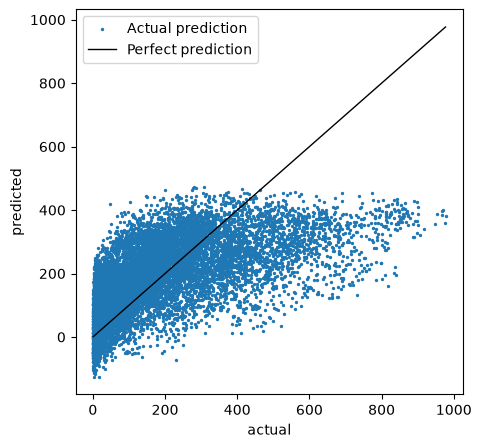

In [22]:
def plotResults(model, X, y):
    """
    A function to plot the predicted values against the actual values
    """
    # Scatter plot of actual vs predicted values
    pd.DataFrame({'actual':y, 'predicted':model.predict(X)})\
        .plot.scatter('actual', 'predicted',
                      figsize=(5, 5), s=2,
                      label='Actual prediction')
    # Plot line of perfect predictions
    plt.plot([y.min(), y.max()],
             [y.min(), y.max()],
             c='black', lw=1,
             label='Perfect prediction')
    # Add legend
    plt.legend()

plotResults(lr, X, y)

In exercise 02 we already had a preview on model evaluation for binary classification models. Here we looked at the confusion matrix binary classification metrics. For regression models we have to use different metrics. Here we want to have a look at four of the most popular regression metrics. With the vector of predictions $\hat y$, the vector of actual values $y$ and a total of $n$ observations, they can be defined as follows.

Mean absolute error ($\mathrm {MAE}$)

$$\mathrm {MAE} = \frac{1}{n} \sum _{i=1}^{n} \left| y_{i}-\hat{y}_{i} \right| $$

Mean squared error ($\operatorname{MSE}$)

$$\operatorname {MSE} ={\frac {1}{n}}\sum _{i=1}^{n}\left(y_{i}-{\hat {y}_{i}}\right)^{2}$$

Root-mean-square error $ \operatorname {RMSE}$

$$ \operatorname {RMSE} ={\sqrt {\operatorname {MSE}}}$$

Coefficient of determination $\operatorname{R}^2$:

with Residual sum of squares $\operatorname{RSS} = \sum _{i=1}^{n}\left(y_{i}-{\hat {y}_{i}}\right)^{2}$ and

Total sum of squares $\operatorname{TSS} = \sum _{i=1}^{n}\left(y_{i}-{\bar {y}}\right)^{2}$.

$$\operatorname{R}^{2}=1-\frac{\operatorname{RSS}}{\operatorname{TSS}}$$

Implementations of these functions can be imported from `sklearn.metrics`.

In [23]:
# Import metric functions for evaluation
from sklearn.metrics import mean_absolute_error,\
                            mean_squared_error,\
                            root_mean_squared_error,\
                            r2_score
# Make predictions
y_pred = lr.predict(X)

In [24]:
# Evaluate metrics
mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
rmse = root_mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

# Print results
print(f'MAE:  {mae}\nMSE:  {mse}\nRMSE: {rmse}\nR^2:  {r2}')

MAE:  106.01333621617424
MSE:  20300.829671946412
RMSE: 142.48098003574518
R^2:  0.3795419702604197


Let's wrap that into a function, so we can use it later for the evalution of other models.

In [88]:
def evaluate(y, y_pred):
    """
    Function to evaluate regression results.
    Params:
        y: the ground truth vector
        y_pred: the vector of predictions
    """
    mae = mean_absolute_error(y, y_pred)
    mse = mean_squared_error(y, y_pred)
    rmse = root_mean_squared_error(y, y_pred)
    r2 = r2_score(y, y_pred)
    print(f'MAE:  {mae}\nMSE:  {mse}\nRMSE: {rmse}\nR^2:  {r2}')

To asses the final results, we have to put the values of our metrics to the actual distribution.

In [26]:
# Compare results to the actual values
y.describe().iloc[1:] # y.plot.box(vert=False, figsize=(3,2))

mean    188.849286
std     180.892008
min            1.0
25%           40.0
50%          142.0
75%          278.0
max          977.0
Name: cnt, dtype: Float64

Conclusion: The computed metrics of the models is not that high, right? If you look at the features again and remember that we are using a linear model, this is not really surprising. It is hard to find a trend in the data that could be explained linearly.

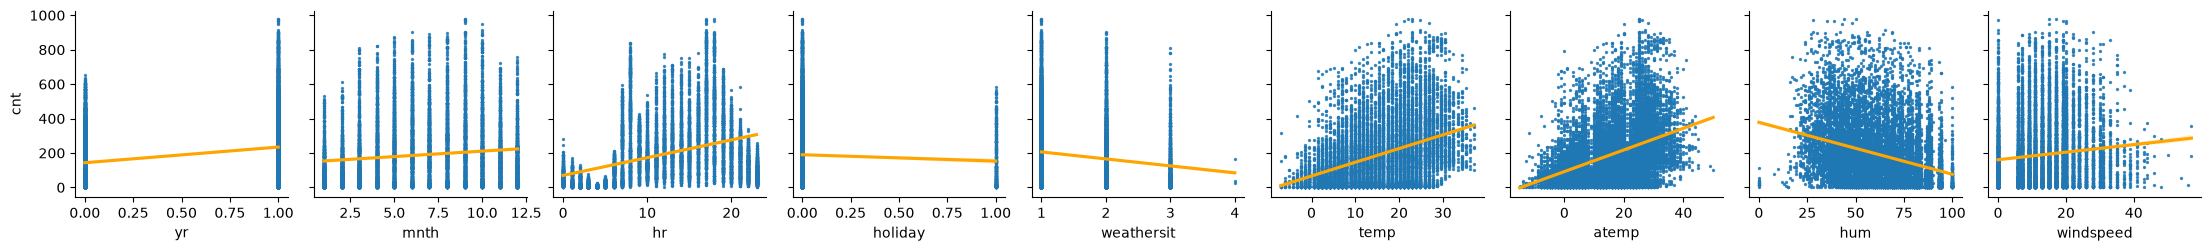

In [27]:
# Make regression plot for all individual independent variables against the dependent
sns.pairplot(
    df_complete,
    y_vars=['cnt'],
    x_vars=X.columns,
    kind='reg',
    plot_kws={'scatter_kws':{'s':2}, 'line_kws':{'color':'orange'}}
)

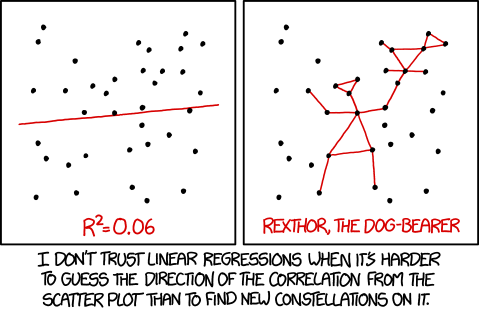



<div style="text-align:center;"><a href="https://www.pinterest.de/pin/327214729167887099/">Source</a></div>

## Logistic Regression

Logistic regression can be considered as a extension of the linear regresion model for binary classification tasks. We use it, if the output variable is categorical, typically with two possible classes (e.g., yes/no, true/false). Unlike linear regression, which predicts continuous outcomes, logistic regression predicts the probability that an input point belongs to a particular class.

The core idea behind logistic regression is to use the logistic function (also known as the sigmoid function) to transform a linear combination of input features into a probability value between 0 and 1. This probability can then be thresholded to make a binary classification decision.

Mathematically, logistic regression models the probability $P(y=1|x)$ as:

$$P(y=1|x) = \frac{1}{1 + e^{-(a + bx_1 + cx_2 + dx_3 + \dots)}}$$

where $ a, b, c, \dots $ are the coefficients that need to be estimated from the data, and $x_1, x_2, x_3, \dots$ are the input features.


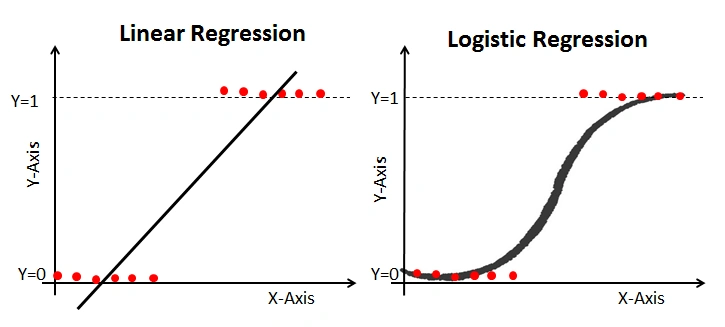

Your next task will be to fit a logistic regression model to the UCI heart disease dataset. For simplicity we want to perform a binary classification. Luckily we can transform our target variable to a binary classification quite easily.

| Encoding | Disease |
|---|---|
| `0` | no heart disease|
| `1` | mild heart disease|
| `2` | moderate heart disease|
| `3` | severe heart disease|
| `4` | critical heart disease

If we consider a value of 0 to represent the absence of a heart disease and values greater than 0 to represent class 1, we have a binary classification of disease or no disease.

In [50]:
# Binarize target variable
df_uci['num'] = df_uci['num'] > 0

For a binary classifcation task, you will for sure also need other metrics to evaluate the model. You've already seen some examples in exercise 02. We can import the logistic regression model, as well as the scikit learn implementations of our evaluation metrics as follows:

In [29]:
# Import logistic regression and classifiction evaluation functions
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

###Confusion Matrix & Classification Metrics

A **confusion matrix** summarizes how well a classification model performs by comparing predicted labels with the true labels.

### Confusion Matrix

|                        | **Predicted Positive** | **Predicted Negative** |
|------------------------|-------------------------|-------------------------|
| **Actual Positive**    | **TP** (True Positive)  | **FN** (False Negative) |
| **Actual Negative**    | **FP** (False Positive) | **TN** (True Negative)  |

### Definitions
- **TP – True Positive:**   Model predicts positive and the sample is actually positive.  
- **FP – False Positive:**  Model predicts positive but the sample is actually negative.  
- **TN – True Negative:**   Model predicts negative and the sample is actually negative.  
- **FN – False Negative:**  Model predicts negative but the sample is actually positive.  

---

### Metrics

#### **Accuracy**
How many predictions the model got correct overall.

$ \text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} $

#### **Precision**
Out of all predicted positives, how many were actually positive.

$\text{Precision} = \frac{TP}{TP + FP}$

#### **Recall**
Out of all actual positives, how many were detected correctly.

$\text{Recall} = \frac{TP}{TP + FN}$


### Exercise 2:

You will now gain hands-on experience by training your first machine learning model in this lecture.

1. Drop observations with missing values from the UCI dataset
2. Split the dataset into feature matrix and target variable
3. Train a logistic regression model
4. Evaluate you model using accuracy, percision, recall and a confusion matrix.

In [53]:
# Drop missing values and split to feature matrix and target variable
df_uci_complete = df_uci.dropna()

X_uci = df_uci_complete.select_dtypes('number')
y_uci = df_uci_complete['num']
X_uci

,age,trestbps,chol,thalch,oldpeak,ca
id,,,,,,
1,63,145.0,233.0,150.0,2.3,0.0
2,67,160.0,286.0,108.0,1.5,3.0
3,67,120.0,229.0,129.0,2.6,2.0
4,37,130.0,250.0,187.0,3.5,0.0
5,41,130.0,204.0,172.0,1.4,0.0
...,...,...,...,...,...,...
300,68,144.0,193.0,141.0,3.4,2.0
301,57,130.0,131.0,115.0,1.2,1.0
302,57,130.0,236.0,174.0,0.0,1.0


In [63]:
# Fit the 
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_uci, y_uci)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [65]:
# Make predictions and compute the confusion matrix
y_pred = log_reg.predict(X_uci)
confusion_matrix(y_uci, y_pred)

array([[137,  23],
       [ 44,  95]])

In [66]:
# Compute and print metrics
evaluate(y_uci, y_pred)

MAE:  0.22408026755852842
MSE:  0.22408026755852842
RMSE: 0.4733711731385092
R^2:  0.09923561151079141


### Adjusting the Classification Threshold in Logistic Regression

A logistic regression model outputs **probabilities**, not direct class labels.  
By default, predictions are classified as **positive if the probability ≥ 0.5**.  
However, we can change this *threshold* to make the model more or less sensitive.

- A **lower threshold** → more positives predicted (higher recall, lower precision).  
- A **higher threshold** → fewer positives predicted (higher precision, lower recall).  


In [67]:
# Predict probabilities instead of labels
y_proba = log_reg.predict_proba(X_uci)[:, 1]   # probability of class 1

# Choose a custom threshold
threshold = 0.2   # try values like 0.3, 0.5, 0.7

# Convert probabilities to class predictions
y_pred_custom = (y_proba >= threshold).astype(int)

# Evaluate the model
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score

print("Accuracy:", accuracy_score(y_uci, y_pred_custom))
print("Precision:", precision_score(y_uci, y_pred_custom))
print("Recall:", recall_score(y_uci, y_pred_custom))
print("Confusion Matrix:\n", confusion_matrix(y_uci, y_pred_custom))

Accuracy: 0.6521739130434783
Precision: 0.57847533632287
Recall: 0.9280575539568345
Confusion Matrix:
 [[ 66  94]
 [ 10 129]]


### Exercise 3:

Write a function that:

1. Takes the true labels and predicted probabilities from a logistic regression model.  
2. Evaluates **precision**, **recall**, and **accuracy** for thresholds from 0.0 to 1.0 (step 0.01).  
3. Stores each metric in a list.  
4. Plots all three metrics in one figure, with:
   - x-axis → threshold  
   - y-axis → metric value  

Run your function using the predicted probabilities from your trained logistic regression model.

c:\Users\anton_zkhbygp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\anton_zkhbygp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\anton_zkhbygp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

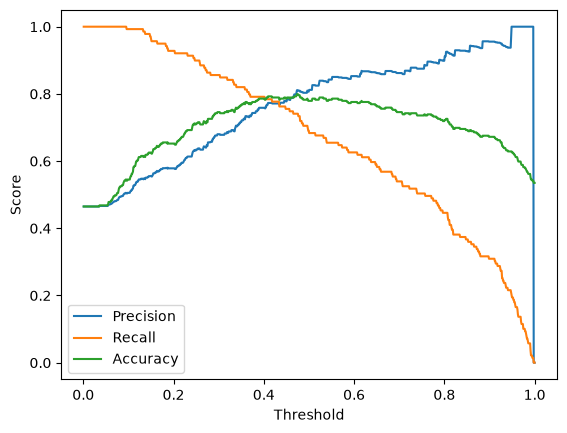

[(np.float64(0.001), 0.46488294314381273, 1.0, 0.46488294314381273), (np.float64(0.002001002004008016), 0.46488294314381273, 1.0, 0.46488294314381273), (np.float64(0.0030020040080160322), 0.46488294314381273, 1.0, 0.46488294314381273), (np.float64(0.004003006012024048), 0.46488294314381273, 1.0, 0.46488294314381273), (np.float64(0.0050040080160320645), 0.46488294314381273, 1.0, 0.46488294314381273), (np.float64(0.006005010020040081), 0.46488294314381273, 1.0, 0.46488294314381273), (np.float64(0.007006012024048097), 0.46488294314381273, 1.0, 0.46488294314381273), (np.float64(0.008007014028056113), 0.46488294314381273, 1.0, 0.46488294314381273), (np.float64(0.00900801603206413), 0.46488294314381273, 1.0, 0.46488294314381273), (np.float64(0.010009018036072147), 0.46488294314381273, 1.0, 0.46488294314381273), (np.float64(0.01101002004008016), 0.46488294314381273, 1.0, 0.46488294314381273), (np.float64(0.012011022044088177), 0.46488294314381273, 1.0, 0.46488294314381273), (np.float64(0.0130

In [89]:
def evaluate_logical(y, y_pred):
    list_of_metrics = []
    interval = np.linspace(0.001, 1, 999)
    for threshold in interval :
        y_pred_custom = (y_pred >= threshold).astype(int)
        precision = precision_score(y, y_pred_custom)
        recall = recall_score(y, y_pred_custom)
        accuracy = accuracy_score(y, y_pred_custom)
        list_of_metrics.append((threshold, precision, recall, accuracy))

    plt.plot([x[0] for x in list_of_metrics], [x[1] for x in list_of_metrics], label='Precision')
    plt.plot([x[0] for x in list_of_metrics], [x[2] for x in list_of_metrics], label='Recall')
    plt.plot([x[0] for x in list_of_metrics], [x[3] for x in list_of_metrics], label='Accuracy')

    plt.xlabel('Threshold')
    plt.ylabel('Score')
    plt.legend()

    plt.show()
    print(list_of_metrics)

 
evaluate_logical(y_uci, y_proba)



## Decision Trees

The goal of decision trees (DTs) is to create a model that predicts the value of a target variable by learning simple decision rules inferred from the inputs.

We use decision trees every day from childhood, when we need to choose one option from many possible variants. For example, this could be a possible decision tree for deciding on evening plans:

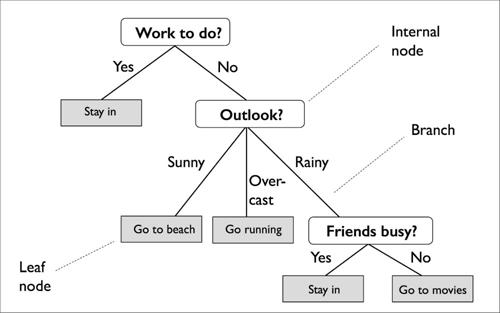

### Manual Example

However, decision trees can be used not only for classification tasks (such as deciding whether to stay in or go for a run) but for regression tasks as well. This means that we can predict continuous values.

As a first example, we could try using our 'expert knowledge' to create our own decision tree based on simple decision rules.

In [90]:
def myDecisionTree(x):
    """
    Computes an 'expert knowledge'-based prediction for a single observation.
    Predictions are based on the time of day and whether or not it is a working day.
    """
    # If it is in between 1 and 6 in the morning, most
    # of the people might sleep. Let's use a low value!
    if 1 < x['hr'] < 6:
        return 10

    # WEEKEND OR HOLIDAY
    if x['dteday'].weekday() >= 5 or x['holiday']:
        # During weekend we might have more users in the afternoon
        if 12 <= x['hr'] <= 17:
            return 360
        else:
            return 150

    # WORKING DAY
    # On workingdays we might have the most use during rush hour
    # at 8 in the morning and 17-18 in the evening
    elif x['hr'] in [8, 17, 18]:
        return 480

    # if nothing of our condition fit, we simply return the mean
    return 130

# Make predictions and evaluate them
tmp = df[~df['cnt'].isnull()]
evaluate(tmp['cnt'], tmp.apply(myDecisionTree, axis=1))

MAE:  97.44054038383487
MSE:  18526.08459442222
RMSE: 136.11056018701203
R^2:  0.43643985923197914


In fact, with just a few rules and a little intuition, we achieved a result that was even better than our first approach with the linear regression model. Manually implementing an expert system is a valid approach. However, we want to use machine learning here to automatically extract relationships in the data. To do this, we can train a decision tree.

### Shallow Decision Tree and Visualisation

The process of solving regression problems with decision trees using Scikit Learn is very similar to that of the multiple linear regression. However we use the `DecisionTreeRegressor` class of the tree library.

In [91]:
# Import the decision tree regressor and plot function
from sklearn.tree import DecisionTreeRegressor, plot_tree

The decision tree model has many hyperparameters that can be used to control the fitting process and the final shape of the tree. For our first example, we want a small decision tree that can be easily visualised. Therefore, we set the `max_depth` parameter to 3 and use only the features `hr` and `temp`.

We can visualise our decision tree using the `plot_tree` function.

MAE:  89.56161693038818
MSE:  17168.81727654514
RMSE: 131.0298335362796
R^2:  0.475266247118721


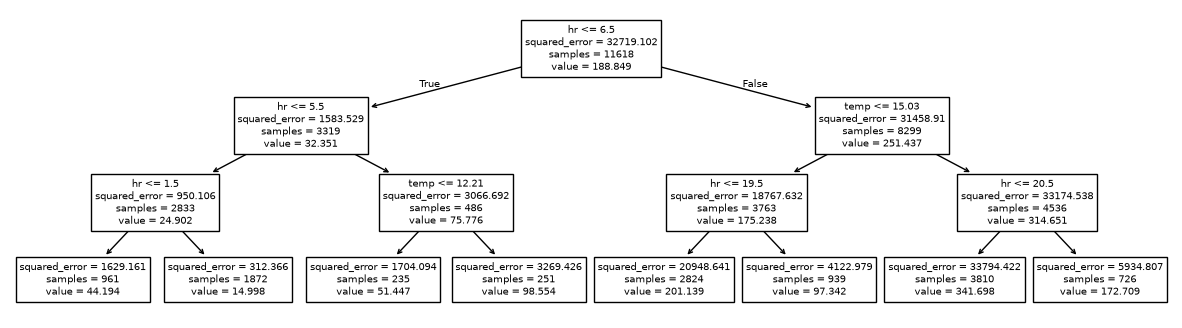

In [93]:
# Instantiate and fit model
shallow_tree = DecisionTreeRegressor(max_depth=3, random_state=42)
shallow_tree.fit(X[['hr', 'temp']], y)

# Evaluate the model
evaluate(y, shallow_tree.predict(X[['hr', 'temp']]))

# Plot the decision tree
plt.figure(figsize=(15, 4))
plot_tree(shallow_tree, feature_names=['hr', 'temp']);

In fact, if we have a two-dimensional input space (as we do here, with two features), we can visualise how a decision tree partitions the input space into smaller rectangles. The decision tree assigns individual values to each of these partitions.

Don't be frightened by the following code — you don't need to understand exactly what's happening. All you need to know is that we can use the decision rules of the tree to calculate the decision boundaries in the two-dimensional input space.

In [94]:
def getCmap(values, cmap=None):
    """
    Returns a wrapper around a cmap, that performs
    normalization according to the range of values.
    """
    if cmap is None: cmap = plt.colormaps.get('viridis')
    mi,ma = min(values),max(values)
    return lambda value: cmap((value - mi) / (ma - mi))

def plotData(X, feature_names, rules, values, ax=None, cmap=None):
    """
    Creates a scatter plot for the data according to the decision rules.
    """
    if ax is None: fig,ax = plt.subplots()
    if cmap is None: cmap = getCmap(values)

    # Iter rules and values for all leave nodes
    for rule,value in zip(rules, values, strict=True):
        data = X # Dataframe slice according to decision rule
        bounds = [] # Pretty print representation of dicision rules

        # Iter features
        for f,(mi,ma) in rule.items():
            if mi is not None: data = data[data[f] > mi]
            if ma is not None: data = data[data[f] <= ma]
            bounds.append((f'{mi:.2f}<' if mi else '') + f
                          + (f'<={ma:.2f}' if ma else ''))

        # Plot scatter points
        data.plot.scatter(*feature_names, color=cmap(value), label='\n AND '.join(bounds), ax=ax)

#plotData(X_all, feature_names, rules, values=range(len(rules)))

In [95]:
def plotDecisionBoundaries(X, feature_names, rules, values, class_names=None, ax=None, cmap=None, set_lims=True):
    """
    Plot boundary boxes for each of the leave nodes
    as specified by the params rules and values.
    """
    if ax is None: fig,ax = plt.subplots()
    if cmap is None: cmap = getCmap(values)

    # feature names for x and y axis
    x,y = feature_names

    # Total range of the provided data
    ranges = X[x].aggregate(['min', 'max']), X[y].aggregate(['min', 'max'])

    # Iter rules and values for all leave nodes
    for rule, value in zip(rules, values):

        # Compute the bounds of the current leaf node (x-/y- min/max)
        def get_bounds(feature_name_idx):
            b = rule.get(feature_names[feature_name_idx], [None, None]).copy()
            if b[0] is None: b[0] = ranges[feature_name_idx].iloc[0]
            if b[1] is None: b[1] = ranges[feature_name_idx].iloc[1]
            return b
        x_bounds = get_bounds(0)
        y_bounds = get_bounds(1)

        width = x_bounds[1] - x_bounds[0]
        height = y_bounds[1] - y_bounds[0]

        # Draw value in the bounding box center
        ax.text(x_bounds[0] + width/2, y_bounds[0] + height/2,
                f'{value:.2f}' if class_names is None else class_names[value],
                horizontalalignment='center', verticalalignment='center', rotation=90,
                bbox=dict(facecolor='white', alpha=0.4, edgecolor='white', boxstyle='round,pad=.2'))

        # Draw rectangle of decision bounds
        ax.add_patch(mpl.patches.Rectangle((x_bounds[0], y_bounds[0]),
                                           width, height,
                                           color=cmap(value), alpha=.2))

    # Add label and axis limits
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    if set_lims:
        ax.set_xlim(*ranges[0])
        ax.set_ylim(*ranges[1])

#plotDecisionBoundaries(X_all, feature_names, rules, range(len(rules)))

In [96]:
def plotDecisionTree2D(dt, X, class_names=None):
    """
    Plots a 2 dimsional representation of a decision tree with two features.
    Params:
        dt: an sklearn decision tree
        X: the feature matrix as a Pandas dataframe
        class_names=None: only used for classification to specify the class names.
            If None, the class names are infered from the DecisionTreeClassifier
    """
    tree = dt.tree_
    max_depth = tree.max_depth
    featureInidices = np.unique(tree.feature[tree.feature >= 0])
    assert len(featureInidices) <= 2
    feature_names = X.columns[featureInidices]
    is_classification = hasattr(dt, 'classes_')

    n_nodes = 0
    stack = []
    rules = []
    values = []

    # Iter tree in depth-first search
    for i, (threshold, feature, value, depth) in enumerate(zip(
        tree.threshold, tree.feature,
        tree.value.argmax(axis=-1)[:,0] if is_classification else tree.value[:,0,0],
        tree.compute_node_depths()
    )):
        # Return from deeper subtree
        while len(stack) > depth - 1:
            stack.pop()

        # Found a leave node
        if feature == -2:
            values.append(value)

            # Construct rule by iterating
            # the thresholds and feature_indices of the path from the root node to the current leave
            rule = {}
            for (t,f),isLarger in zip(stack, map(int, str(bin(n_nodes))[2:].zfill(max_depth))):

                feature_name = X.columns[f]
                if not feature_name in rule: rule[feature_name] = [None,None]

                # isLarger determines if a path went left or right (smaller or larger than threshold)
                rule[feature_name][not isLarger] = t

            rules.append(rule)
            n_nodes += 1

        # Went deeper
        if depth > len(stack):
            stack.append((float(threshold), int(feature)))

    # Create figure and colormap
    fig, ax = plt.subplots()
    cmap = plt.colormaps.get('viridis')
    cmap_wrapper = getCmap(values, cmap=cmap)

    # Plot
    class_names = (dt.classes_ if is_classification else None) if class_names is None else class_names
    plotDecisionBoundaries(X, feature_names, rules.copy(), values, class_names=class_names,
                           ax=ax, cmap=cmap_wrapper, set_lims=False)
    plotData(X, feature_names, rules.copy(), values, ax=ax, cmap=cmap_wrapper)

    # Add colorbar and legend
    if not is_classification:
        fig.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(tree.value.max(), tree.value.min()), cmap=cmap), ax=ax)
    ax.legend(loc=(1.02 if is_classification else 1.3, .1), title='Decision rules')

    return feature_names, rules

# feature_names, rules = plotDecisionTree2D(dt_shallow, X_all)

The following plots show us the decision tree itself and it's visual projection on the two-dimensional input space of `temp` and `hr`. We can see, how the decision rules (visible in the legend), divide the feature space in small partitions.

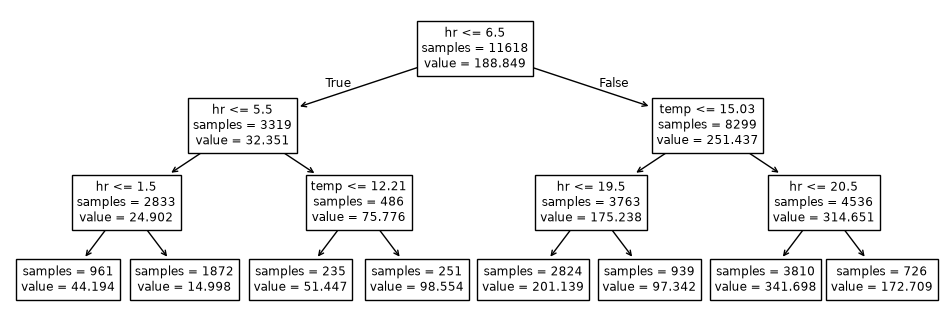

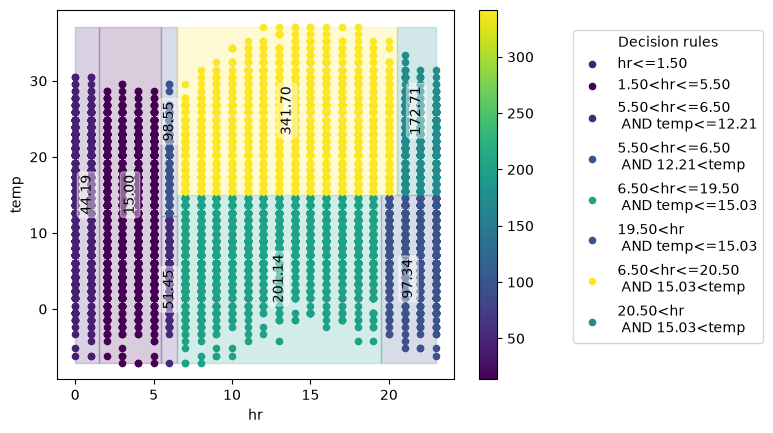

In [97]:
# Plot decision tree
plt.figure(figsize=(12, 4))
plot_tree(shallow_tree, feature_names=['hr', 'temp'], impurity=False) # plot as tree
plotDecisionTree2D(shallow_tree, X[['hr', 'temp']]); # plot decision boundaries

### Decision Tree Regression

Now that we understand how decision trees make predictions, we can finally train a model in the whole feature set. In fact decision trees can handle missing values (in contrast to a linear regression model), but for now we simple can fit a final model to our feature set `X` again.

Number of leave nodes: 11181
Maximum depth:  32
---------------------------
MAE:  0.3170941642279222
MSE:  40.957049406093994
RMSE: 6.3997694806995975
R^2:  0.9987482220880082


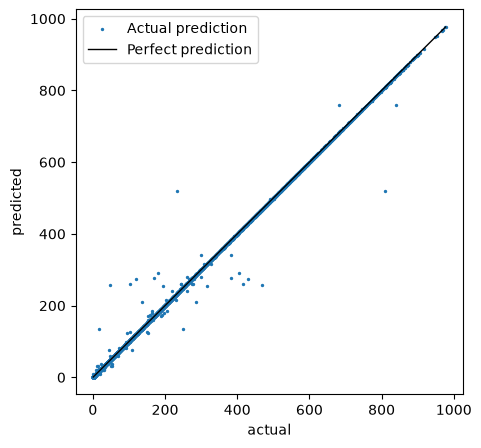

In [98]:
# Fit decision tree regressor
dt = DecisionTreeRegressor()
dt.fit(X, y)

# Print shape summary descrition
print('Number of leave nodes:', dt.tree_.n_leaves)
print('Maximum depth: ', dt.tree_.max_depth)
print('---------------------------')

# Plot actual against predicted values
plotResults(dt, X, y)

# Print evaluation
evaluate(y, dt.predict(X))

That's incredible, isn't it? We built a decision tree regressor, and compared to the linear regression model, it seems to make really good predictions! **In fact, the predictions are so good that we should start to question them.**

### Exercise 4:

For sure there is also a decision tree implementation for classification.
* Train a shallow decision tree classifier using only the features `['chol', 'age']` and `max_depth=3`

    * Evaluate the results (you can use the `evaluate_classification` function for that)
      
    * Plot the tree using the `plot_tree` and the `plotDecisionTree2D` functions

* Train a second decision tree model using the whole feature matrix and the default model hyperparameters
    * Evaluate the results (you can use the `evaluate_classification` function for that)

MAE:  0.41228472923444864
MSE:  0.20614236461722432
RMSE: 0.45402903499360514
R^2:  0.17134291640537447


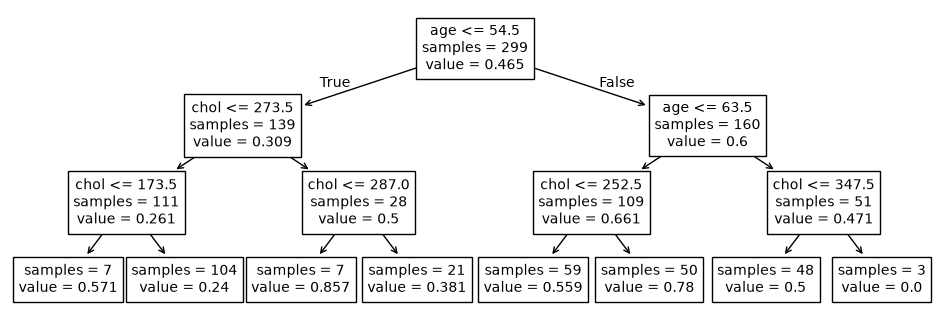

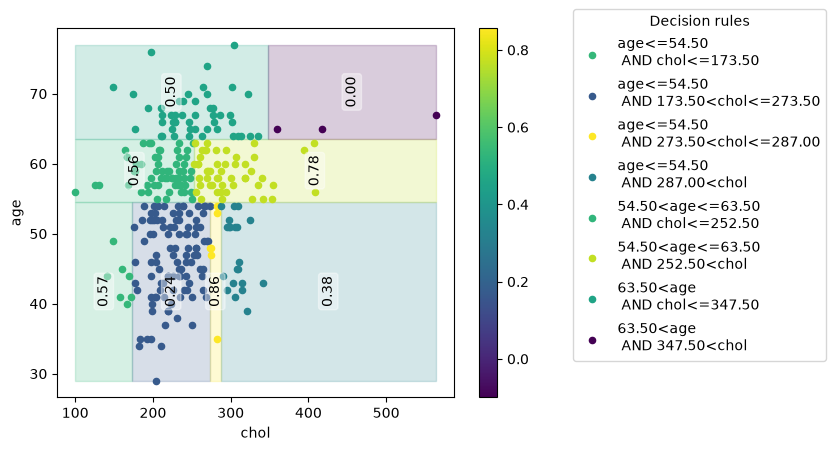

In [108]:
def evaluate_classification(classifier, X, y):
    """
    Function to evaluate a classification model.
    Params:
        classifier: an sklearn classification model
        X: the feature matrix used for evaluation (a Pandas dataframe)
        y: the ground thruth vector used for evaluation
    """

    # Make predictions and compute the confusion matrix
    y_pred = classifier.predict(X)
    print('Confusion matrix:')
    print(confusion_matrix(y, y_pred))

    # Compute and print metrics
    print('Accuracy:', accuracy_score(y, y_pred))
    print('Precision:', precision_score(y, y_pred))
    print('Recall:', recall_score(y, y_pred))

MAE:  0.41228472923444864
MSE:  0.20614236461722432
RMSE: 0.45402903499360514
R^2:  0.17134291640537447
Confusion matrix:


ValueError: Classification metrics can't handle a mix of binary and continuous targets

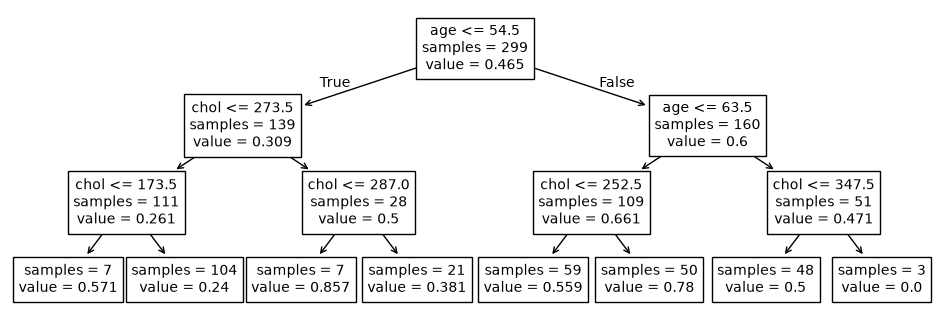

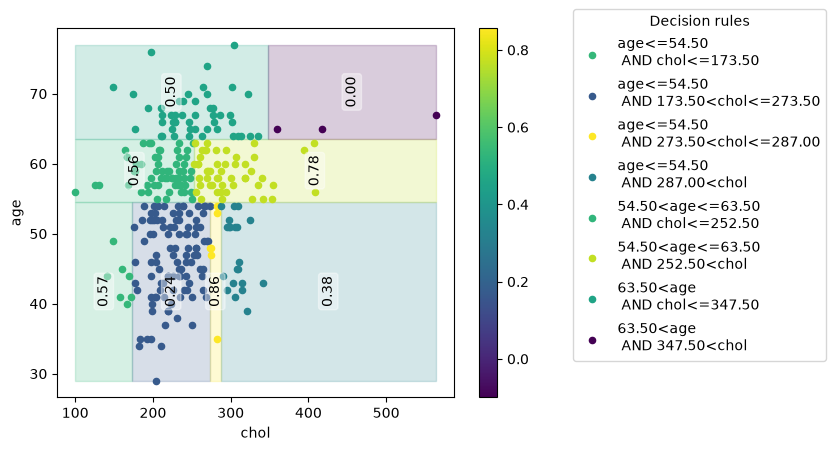

In [122]:
# Instantiation and training
shallow_tree.fit(X_uci[['chol', 'age']], y_uci)
evaluate(y_uci, shallow_tree.predict(X_uci[['chol', 'age']]))

plt.figure(figsize=(12, 4))
plot_tree(shallow_tree, feature_names=['chol', 'age'], impurity=False)
plotDecisionTree2D(shallow_tree, X_uci[['chol', 'age']]);


# Evaluation

# Plots:

# Plot tree

# Plot boundary boxes
evaluate_classification(shallow_tree, X_uci[['chol', 'age']], y_uci)

In [119]:
# Instantiate and train decision tree classifier
dt.fit(X_uci, y_uci)
evaluate_classification(dt, X_uci, y_uci)

# Print shape summary descrition
print('Number of leave nodes:', classifier.tree_.n_leaves)
print('Maximum depth: ', classifier.tree_.max_depth)
print('---------------------------')

# Evaluate results


Confusion matrix:
[[160   0]
 [  0 139]]
Accuracy: 1.0
Precision: 1.0
Recall: 1.0


NameError: name 'classifier' is not defined